# Análise exploratória — Agrupamento de produtos (K-Means)

Aprendizado não supervisionado sobre os produtos de **uma importação**, buscando identificar agrupamentos naturais que possam **reforçar ou refinar** a classificação por regras do módulo 4 (`app/services/classificacao_estoque.py`).

Para a comparação ser justa, o notebook enxerga os produtos exatamente como o módulo 4:

- **Mesmo recorte:** uma importação por vez — a classificação é relativa ao lote, então misturar importações compararia escalas diferentes.
- **Mesmas dimensões:** custo gerencial composto, giro (90d) e nível de estoque relativo ao mínimo.
- **Mesma normalização:** rank relativo (0 a 1) dentro do lote, com o giro invertido (giro baixo = mais prioridade).
- **Sem o `score_prioridade` como feature:** ele é derivado dessas mesmas dimensões e é o que define a classificação — usá-lo puxaria os clusters para a própria regra e inflaria a concordância.
- **Sem os pesos da regra no agrupamento:** o K-Means vê as 3 dimensões com o mesmo peso. Os pesos do módulo 4 (40% custo, 40% giro, 20% estoque) só entram para dar nome aos clusters — assim, se os métodos concordarem, não é porque o K-Means herdou os pesos.

> **Histórico:** com os pesos iguais originais (1/3 cada), este notebook mostrou concordância de só 46% — o nível de estoque andava na direção oposta de custo e giro e anulava as duas, deixando 48 de 56 produtos em "Média". Isso motivou a mudança para 40/40/20 no módulo 4.

Notebook standalone: não depende do código da API, só lê os dados direto do Supabase usando as credenciais de `backend/.env`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import dotenv_values
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from supabase import create_client

config = dotenv_values(Path("..") / ".env")
supabase = create_client(config["SUPABASE_URL"], config["SUPABASE_KEY"])

# None = usa a importação concluída mais recente (a mesma que o dashboard exibe).
# Para analisar outra, cole aqui o id dela.
IMPORTACAO_ID = None

# Abaixo disso o K-Means não tem base estatística (silhouette e cotovelo oscilam demais).
MIN_PRODUTOS = 10

## 1. Carregar os dados da importação

Mesma consulta que a API usa em `GET /importacoes/{id}/resultados` (`listar_resultados_por_importacao`).

In [2]:
if IMPORTACAO_ID is None:
    ultima = (
        supabase.table("importacoes")
        .select("id, nome_arquivo, concluida_em")
        .in_("status", ["concluida", "concluida_com_erros"])
        .order("concluida_em", desc=True)
        .limit(1)
        .execute()
    )
    if not ultima.data:
        raise RuntimeError("Nenhuma importação concluída encontrada.")
    IMPORTACAO_ID = ultima.data[0]["id"]
    print(f"Importação mais recente: {ultima.data[0]['nome_arquivo']} ({ultima.data[0]['concluida_em']})")

resposta = (
    supabase.table("estoque_snapshots")
    .select(
        "quantidade_estoque_atual, estoque_minimo, "
        "produtos(codigo_produto, nome_produto, categoria), "
        "resultados_analise(custo_gerencial_composto, giro_30d, giro_90d, giro_180d, "
        "classificacao, score_prioridade, desconto_maximo_percentual)"
    )
    .eq("importacao_id", IMPORTACAO_ID)
    .execute()
)

registros = []
for snapshot in resposta.data:
    resultado = snapshot["resultados_analise"]
    if isinstance(resultado, list):  # relação 1:1 pode vir como lista dependendo do PostgREST
        resultado = resultado[0] if resultado else None
    if resultado is None:
        continue
    registros.append({
        **snapshot["produtos"],
        "quantidade_estoque_atual": snapshot["quantidade_estoque_atual"],
        "estoque_minimo": snapshot["estoque_minimo"],
        **resultado,
    })

df = pd.DataFrame(registros)

colunas_numericas = [
    "custo_gerencial_composto", "giro_30d", "giro_90d", "giro_180d",
    "score_prioridade", "desconto_maximo_percentual",
    "quantidade_estoque_atual", "estoque_minimo",
]
df[colunas_numericas] = df[colunas_numericas].apply(pd.to_numeric)

print(f"{len(df)} produtos carregados da importação {IMPORTACAO_ID}")
if len(df) < MIN_PRODUTOS:
    raise RuntimeError(
        f"Dados insuficientes: {len(df)} produtos (mínimo {MIN_PRODUTOS}) — "
        "o agrupamento não seria confiável."
    )
df.head()

Importação mais recente: estoque_mock_stockwise (1).csv (2026-10-25T19:45:03.46935+00:00)
56 produtos carregados da importação 4d7e25ae-3769-462b-a1e0-df05b951213d


,categoria,nome_produto,codigo_produto,quantidade_estoque_atual,estoque_minimo,giro_30d,giro_90d,giro_180d,classificacao,score_prioridade,custo_gerencial_composto,desconto_maximo_percentual
0,Filtros,Filtro de óleo motor 1.0/1.6,AP-1001,42.0,15.0,6.3730,5.8902,5.6971,Prioridade Baixa,0.2291,23.73,25.21
1,Freios,Pastilha de freio dianteira,AP-1002,18.0,10.0,6.0833,5.4074,5.2948,Prioridade Baixa,0.2109,86.81,26.49
2,Suspensão,Amortecedor traseiro,AP-1003,26.0,6.0,0.0000,0.1560,0.2340,Prioridade Alta,0.8691,325.85,7.86
3,Motor,Correia dentada,AP-1004,55.0,20.0,6.6364,5.1616,5.1616,Prioridade Baixa,0.2873,52.38,27.88
4,Ignição,Vela de ignição,AP-1005,120.0,40.0,6.5903,6.0833,5.7454,Prioridade Baixa,0.1982,11.70,35.33


## 2. Preparar features — as mesmas 3 dimensões do módulo 4

Replica `classificar_lote`:

- `giro_90d` nulo (estoque zerado, ver `giro_estoque.py`) vira **0**, como no backend — nenhum produto fica de fora.
- Razão de estoque = `atual / mínimo` (ou `atual` quando o mínimo é 0).
- Cada dimensão vira **rank relativo no lote** (0 = menor, 1 = maior, empates com rank médio) — mesmo cálculo de `_rank_normalizado`. Isso também resolve a diferença de escala (R$ vs. razão) sem `StandardScaler` e deixa a análise robusta a outliers de custo.
- O giro é invertido (`1 − rank`) para as três dimensões apontarem no mesmo sentido: **valor alto = mais prioridade para promoção**.

Nesse espaço, o `score_prioridade` do backend é exatamente a média ponderada das três features (`PESOS`, iguais aos de `classificacao_estoque.py`) — a célula abaixo confere isso. Ou seja: a regra corta o espaço por faixas fixas do score (0,34 e 0,67), enquanto o K-Means procura grupos livremente no mesmo espaço.

In [3]:
def rank_normalizado(serie: pd.Series) -> pd.Series:
    """Equivalente a _rank_normalizado do módulo 4."""
    if len(serie) <= 1:
        return pd.Series(0.5, index=serie.index)
    return (serie.rank(method="average") - 1) / (len(serie) - 1)


giro = df["giro_90d"].fillna(0)
razao_estoque = df["quantidade_estoque_atual"].where(
    df["estoque_minimo"] <= 0,
    df["quantidade_estoque_atual"] / df["estoque_minimo"].where(df["estoque_minimo"] > 0),
)

df["rank_custo"] = rank_normalizado(df["custo_gerencial_composto"])
df["rank_giro_invertido"] = 1 - rank_normalizado(giro)
df["rank_estoque"] = rank_normalizado(razao_estoque)

FEATURES = ["rank_custo", "rank_giro_invertido", "rank_estoque"]
# Mesmos pesos de PESO_CUSTO / PESO_GIRO / PESO_ESTOQUE no módulo 4.
PESOS = pd.Series([0.4, 0.4, 0.2], index=FEATURES)
X = df[FEATURES].to_numpy()

# Sanidade: as features reproduzem o score calculado pelo backend?
score_recalculado = (df[FEATURES] * PESOS).sum(axis=1).round(4)
divergencia_maxima = (score_recalculado - df["score_prioridade"]).abs().max()
print(f"Diferença máxima entre score recalculado e score do backend: {divergencia_maxima:.4f}")
assert divergencia_maxima <= 0.0001, "Features não batem com o módulo 4 — revisar a preparação."

Diferença máxima entre score recalculado e score do backend: 0.0000


## 3. Escolher k (método do cotovelo + silhouette)

Exploratório: os dois gráficos abaixo ajudam a decidir quantos clusters fazem sentido para os dados — não existe resposta única. Com poucos produtos as curvas oscilam bastante, então leia como indicação, não como prova.

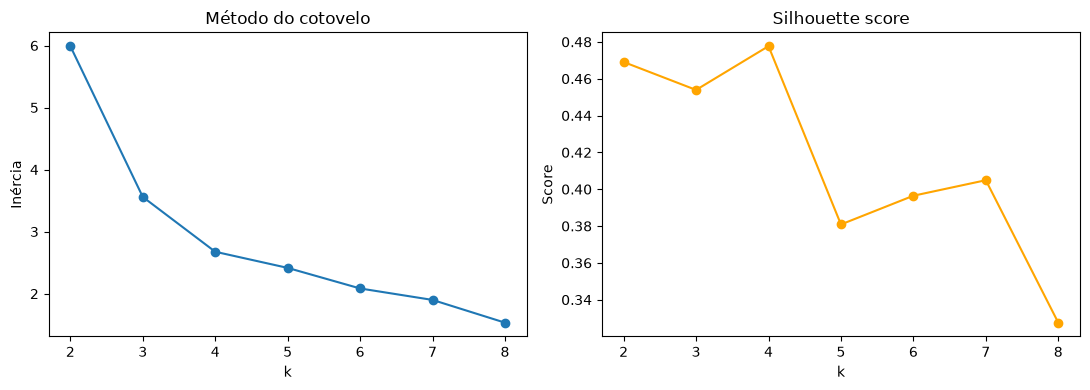

In [4]:
valores_k = range(2, min(8, len(df) - 1) + 1)
inercias = []
silhouettes = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, random_state=42, n_init="auto").fit(X)
    inercias.append(modelo.inertia_)
    silhouettes.append(silhouette_score(X, modelo.labels_))

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].plot(list(valores_k), inercias, marker="o")
eixos[0].set_title("Método do cotovelo")
eixos[0].set_xlabel("k")
eixos[0].set_ylabel("Inércia")

eixos[1].plot(list(valores_k), silhouettes, marker="o", color="orange")
eixos[1].set_title("Silhouette score")
eixos[1].set_xlabel("k")
eixos[1].set_ylabel("Score")

plt.tight_layout()
plt.show()

## 4. Aplicar K-Means e nomear os clusters

`K = 3` por padrão, para comparar diretamente com as 3 classificações do módulo 4. Os rótulos do K-Means (0, 1, 2) são arbitrários, então cada cluster recebe um nome pelo **score do seu centróide** (média ponderada das features com os pesos do módulo 4) — o mesmo critério da regra: centróide mais alto = "Prioridade Alta", mais baixo = "Prioridade Baixa". Assim dá para comparar produto a produto.

In [5]:
K = 3
NOMES_POR_ORDEM = ["Prioridade Baixa", "Prioridade Média", "Prioridade Alta"]

modelo_final = KMeans(n_clusters=K, random_state=42, n_init="auto").fit(X)
df["cluster"] = modelo_final.labels_

centroides = pd.DataFrame(modelo_final.cluster_centers_, columns=FEATURES)
centroides["score_centroide"] = (centroides[FEATURES] * PESOS).sum(axis=1)
ordem = centroides["score_centroide"].sort_values().index

if K == len(NOMES_POR_ORDEM):
    nome_por_cluster = {cluster: NOMES_POR_ORDEM[posicao] for posicao, cluster in enumerate(ordem)}
else:
    nome_por_cluster = {cluster: f"Cluster {posicao + 1}" for posicao, cluster in enumerate(ordem)}
df["grupo_kmeans"] = df["cluster"].map(nome_por_cluster)

colunas_exibidas = [
    "codigo_produto", "nome_produto", "custo_gerencial_composto",
    "giro_90d", "score_prioridade", "classificacao", "grupo_kmeans",
]
df[colunas_exibidas].sort_values(["grupo_kmeans", "score_prioridade"], ascending=[True, False])

,codigo_produto,nome_produto,custo_gerencial_composto,giro_90d,score_prioridade,classificacao,grupo_kmeans
46,AP-1047,Catalisador (conversor catalítico),962.74,0.0000,0.8127,Prioridade Alta,Prioridade Alta
30,AP-1031,Compressor de ar condicionado,790.60,0.0000,0.8055,Prioridade Alta,Prioridade Alta
38,AP-1039,Caixa de direção hidráulica,1026.30,0.0000,0.7836,Prioridade Alta,Prioridade Alta
44,AP-1045,Módulo de injeção eletrônica,781.76,0.0000,0.7618,Prioridade Alta,Prioridade Alta
5,AP-1006,Bomba de combustível elétrica,298.07,0.0000,0.7418,Prioridade Alta,Prioridade Alta
9,AP-1010,Radiador de arrefecimento,427.97,0.0000,0.7418,Prioridade Alta,Prioridade Alta
6,AP-1007,Kit embreagem completo,483.76,1.1587,0.7182,Prioridade Alta,Prioridade Alta
34,AP-1035,Farol dianteiro completo,456.84,0.6759,0.7145,Prioridade Alta,Prioridade Alta
16,AP-1017,Alternador 12V,427.14,0.6759,0.7000,Prioridade Alta,Prioridade Alta
32,AP-1033,Radiador de ar condicionado (condensador),275.79,0.5794,0.6891,Prioridade Alta,Prioridade Alta


## 5. Visualizar: K-Means vs classificação por regra (módulo 4)

Mesmo eixo usado no dashboard (giro × custo gerencial), mas agora com as cores alinhadas: a mesma cor nos dois gráficos significa o mesmo nível de prioridade.

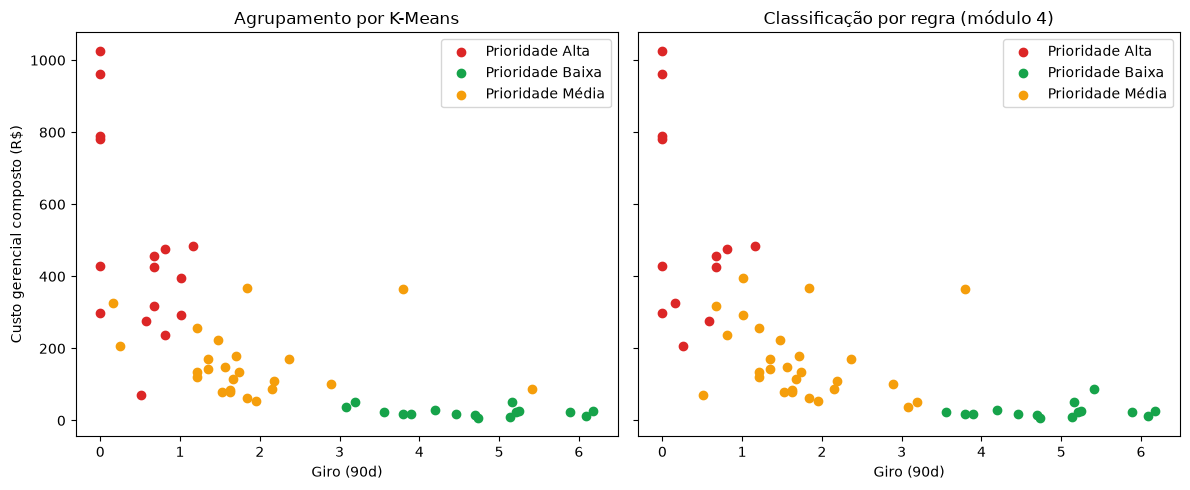

In [6]:
cores_classificacao = {
    "Prioridade Alta": "#dc2626",
    "Prioridade Média": "#f59e0b",
    "Prioridade Baixa": "#16a34a",
}

fig, eixos = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for eixo, coluna, titulo in [
    (eixos[0], "grupo_kmeans", "Agrupamento por K-Means"),
    (eixos[1], "classificacao", "Classificação por regra (módulo 4)"),
]:
    for nome, grupo in df.groupby(coluna):
        eixo.scatter(
            grupo["giro_90d"].fillna(0), grupo["custo_gerencial_composto"],
            label=nome, color=cores_classificacao.get(nome),
        )
    eixo.set_title(titulo)
    eixo.set_xlabel("Giro (90d)")
    eixo.legend()
eixos[0].set_ylabel("Custo gerencial composto (R$)")

plt.tight_layout()
plt.show()

## 6. Interpretar os clusters

Média das dimensões originais e das features por grupo — confirma se o nome dado ao cluster faz sentido (ex.: "Alta" deve ter custo alto e giro baixo).

In [7]:
resumo_clusters = df.groupby("grupo_kmeans").agg(
    quantidade_produtos=("codigo_produto", "size"),
    custo_gerencial_medio=("custo_gerencial_composto", "mean"),
    giro_90d_medio=("giro_90d", "mean"),
    rank_custo=("rank_custo", "mean"),
    rank_giro_invertido=("rank_giro_invertido", "mean"),
    rank_estoque=("rank_estoque", "mean"),
).round(2)
resumo_clusters

,quantidade_produtos,custo_gerencial_medio,giro_90d_medio,rank_custo,rank_giro_invertido,rank_estoque
grupo_kmeans,,,,,,
Prioridade Alta,16,482.56,0.50,0.82,0.84,0.17
Prioridade Baixa,16,24.41,4.66,0.14,0.15,0.82
Prioridade Média,24,158.60,1.84,0.53,0.50,0.51


## 7. O K-Means concorda com a classificação por regra?

In [8]:
ordem_rotulos = [n for n in reversed(NOMES_POR_ORDEM)]
tabela = pd.crosstab(df["grupo_kmeans"], df["classificacao"]).reindex(
    index=ordem_rotulos, columns=ordem_rotulos, fill_value=0
)

concordam = df["grupo_kmeans"] == df["classificacao"]
print(f"Concordância: {concordam.mean():.0%} ({concordam.sum()} de {len(df)} produtos)")
tabela

Concordância: 82% (46 de 56 produtos)


classificacao,Prioridade Alta,Prioridade Média,Prioridade Baixa
grupo_kmeans,,,
Prioridade Alta,11,5,0
Prioridade Média,2,21,1
Prioridade Baixa,0,2,14


### Produtos em que os dois métodos discordam

São os candidatos a revisão manual: o K-Means os agrupou com produtos de outro nível de prioridade. Olhe o `score_prioridade` — divergências perto dos limiares (0,34 e 0,67) são esperadas; divergências longe deles indicam um padrão que a regra não captura.

In [9]:
df.loc[~concordam, colunas_exibidas + FEATURES].sort_values("score_prioridade", ascending=False).round(2)

,codigo_produto,nome_produto,custo_gerencial_composto,giro_90d,score_prioridade,classificacao,grupo_kmeans,rank_custo,rank_giro_invertido,rank_estoque
2,AP-1003,Amortecedor traseiro,325.85,0.16,0.87,Prioridade Alta,Prioridade Média,0.78,0.89,1.00
13,AP-1014,Sensor de oxigênio (sonda lambda),205.38,0.25,0.80,Prioridade Alta,Prioridade Média,0.64,0.87,0.96
45,AP-1046,Silenciador traseiro de escapamento,318.64,0.68,0.66,Prioridade Média,Prioridade Alta,0.76,0.80,0.19
39,AP-1040,Bomba de direção hidráulica,396.25,1.01,0.66,Prioridade Média,Prioridade Alta,0.84,0.72,0.19
12,AP-1013,Amortecedor dianteiro,291.71,1.01,0.62,Prioridade Média,Prioridade Alta,0.73,0.72,0.19
55,AP-1056,Chicote elétrico do motor,236.76,0.81,0.58,Prioridade Média,Prioridade Alta,0.67,0.75,0.05
19,AP-1020,Terminal de direção,71.59,0.51,0.51,Prioridade Média,Prioridade Alta,0.33,0.85,0.19
49,AP-1050,Termostato do motor,37.63,3.08,0.38,Prioridade Média,Prioridade Baixa,0.24,0.31,0.81
22,AP-1023,Tensionador da correia dentada,52.54,3.20,0.37,Prioridade Média,Prioridade Baixa,0.27,0.29,0.71
1,AP-1002,Pastilha de freio dianteira,86.81,5.41,0.21,Prioridade Baixa,Prioridade Média,0.42,0.05,0.11


## Conclusão

- **Concordância alta** e divergências só perto dos limiares → o K-Means **reforça** a regra do módulo 4: os grupos naturais dos dados coincidem com as faixas de score.
- **Divergências longe dos limiares**, ou um cluster que mistura classificações → o score ponderado das 3 dimensões não captura esse padrão. Vale revisar os pesos (hoje 40% custo, 40% giro, 20% estoque) ou os limiares, ou considerar essa informação no cálculo do desconto máximo (módulo 5).